In [1]:
import base64
import html
import io
import json
import os
import random
import re
import time
from pathlib import Path

import pandas as pd
import requests
from google import genai
from google.genai import types
from IPython.display import HTML, display
from PIL import Image

BACKEND_DIR = Path("..").resolve()
TEST_DIR = BACKEND_DIR / "dataset" / "test_ready"
TRAIN_DIR = BACKEND_DIR / "dataset" / "train_ready"
KB_DIR = BACKEND_DIR / "knowledge_base"
REZULTATI_DIR = BACKEND_DIR / "rezultati"

URL = "http://127.0.0.1:8000/identify"
SEED = 42
BROJ_POKUSAJA = 3
PAUZA_POKUSAJ_S = 10

KES_JSON = REZULTATI_DIR / "llm_rag_vs_bez_rag.json"
TABELA_CSV = REZULTATI_DIR / "llm_rag_vs_bez_rag.csv"

server_kod = (BACKEND_DIR / "server.py").read_text(encoding="utf-8")
GEMINI_MODEL = re.search(r'GEMINI_MODEL = "([^"]+)"', server_kod).group(1)
TEMPERATURE = float(re.search(r"temperature=([0-9.]+)", server_kod).group(1))
print("Model:", GEMINI_MODEL, "| temperature:", TEMPERATURE)

SLUCAJEVI = [
    ("A", "short", 0), ("A", "detailed", 0), ("A", "detailed", 0),
    ("B", "", 1),      ("B", "", 3),         ("B", "", 5),
    ("C", "short", 1), ("C", "detailed", 3), ("C", "detailed", 5),
]
IMENA_GRUPA = {"A": "samo tekst", "B": "samo slike", "C": "tekst + slike", "D": "van teme (nije biljka)"}

VAN_TEME_DIR = BACKEND_DIR / "dataset" / "upiti_van_teme"
VAN_TEME = [("zlatni retriver", "pas"), ("kuca", "kuća"), ("orman", "orman")]

Model: gemini-3.5-flash-lite | temperature: 0.2


In [2]:
podela = pd.read_csv(REZULTATI_DIR / "test_podela.csv", dtype=str, keep_default_na=False)
podela["n_slika"] = podela["n_slika"].astype(int)
with open(KB_DIR / "tekst_upiti.json", encoding="utf-8") as f:
    svi_upiti = json.load(f)
imena = pd.read_csv(BACKEND_DIR / "dataset" / "specie_id - scientific_name mapping.csv", dtype=str)
ime_po_id = dict(zip(imena.iloc[:, 0], imena.iloc[:, 1]))

rng = random.Random(SEED)
slucajevi, vec_uzete = [], set()
for grupa, stil, n in SLUCAJEVI:
    kandidati = podela[(podela["grupa"] == grupa) & (podela["stil"] == stil) & (podela["n_slika"] == n)]
    kandidati = kandidati[~kandidati["specie_id"].isin(vec_uzete)]
    red = kandidati.iloc[rng.randrange(len(kandidati))].to_dict()
    vec_uzete.add(red["specie_id"])
    red["opis"] = next(u["upit"] for u in svi_upiti[red["specie_id"]]["test"] if u["stil"] == stil) if stil else ""
    red["fajlovi"] = red["slike"].split("|") if red["slike"] else []
    red["tacna_vrsta"] = ime_po_id[red["specie_id"]]
    red["putanje"] = [TEST_DIR / red["specie_id"] / ime for ime in red["fajlovi"]]
    slucajevi.append(red)

for folder, sta in VAN_TEME:
    fajl = sorted((VAN_TEME_DIR / folder).iterdir())[0]
    slucajevi.append({"specie_id": "van_teme_" + folder.replace(" ", "_"), "grupa": "D", "stil": "", "n_slika": 1,
                      "slike": fajl.name, "opis": "", "fajlovi": [fajl.name], "putanje": [fajl],
                      "tacna_vrsta": f"(nije biljka: {sta})"})

pd.DataFrame(slucajevi)[["grupa", "stil", "n_slika", "specie_id", "tacna_vrsta", "opis"]]

,grupa,stil,n_slika,specie_id,tacna_vrsta,opis
0,A,short,0,0457,Pulsatilla alpina,Small plant about a foot tall with upright whi...
1,A,detailed,0,0164,Ophrys lutea,Wild plant about 40cm high carrying up to 10 l...
2,A,detailed,0,0047,Sedum album,Low creeping plant forming dense mats with fle...
3,B,,1,0042,Lactuca muralis,
4,B,,3,0174,Trifolium rubens,
5,B,,5,0312,Lagenaria siceraria,
6,C,short,1,0126,Nymphaea alba,Large floating white water flower with a yello...
7,C,detailed,3,0360,Cirsium heterophyllum,Unusual spineless plant reaching about knee to...
8,C,detailed,5,0103,Trifolium hybridum,Perennial plant showing compact round flower h...
9,D,,1,van_teme_zlatni_retriver,(nije biljka: pas),


In [3]:
SYSTEM_PROMPT_BEZ_RAG = """You write the final answer of a plant identification system.

You receive a description and/or photos of a plant from a user. Decide which species it is.

Write:
1. "tip": "confident" if you are sure the plant is one particular species, otherwise "uncertain".
2. "uvod": one or two sentences that tell the user the result.
   - "confident": the plant was identified as that species.
   - "uncertain": the system is not sure; these are the most likely species, in order from the most likely.
3. "vrste": for "confident" exactly one species, for "uncertain" at most three species, the most likely first.
   For every species: "naziv" is its scientific name (genus and species, nothing else), and "opis" is two to four
   sentences on how to recognise the plant (flowers, leaves, stem, size).

Write in plain English for a person who is not a botanist. Answer only with JSON."""

SEMA_BEZ_RAG = types.Schema(
    type=types.Type.OBJECT,
    properties={
        "tip": types.Schema(type=types.Type.STRING, enum=["confident", "uncertain"]),
        "uvod": types.Schema(type=types.Type.STRING),
        "vrste": types.Schema(
            type=types.Type.ARRAY,
            items=types.Schema(
                type=types.Type.OBJECT,
                properties={
                    "naziv": types.Schema(type=types.Type.STRING),
                    "opis": types.Schema(type=types.Type.STRING),
                },
                required=["naziv", "opis"],
            ),
        ),
    },
    required=["tip", "uvod", "vrste"],
)

gemini = genai.Client(api_key=os.environ["GEMINI_API_KEY"],
                      http_options=types.HttpOptions(timeout=30_000))


def bez_raga(red):
    delovi = [types.Part.from_bytes(data=p.read_bytes(), mime_type="image/png" if p.suffix.lower() == ".png" else "image/jpeg")
              for p in red["putanje"]]
    delovi.append(f"User description: {red['opis']}" if red["opis"] else "The user gave no description, only photos.")

    for pokusaj in range(BROJ_POKUSAJA):
        try:
            odgovor = gemini.models.generate_content(
                model=GEMINI_MODEL,
                contents=delovi,
                config=types.GenerateContentConfig(
                    system_instruction=SYSTEM_PROMPT_BEZ_RAG,
                    temperature=TEMPERATURE,
                    response_mime_type="application/json",
                    response_schema=SEMA_BEZ_RAG,
                    automatic_function_calling=types.AutomaticFunctionCallingConfig(disable=True),
                ),
            )
            return json.loads(odgovor.text or "")
        except Exception as e:
            print("  pokušaj", pokusaj + 1, "nije uspeo:", type(e).__name__)
            if pokusaj == BROJ_POKUSAJA - 1:
                raise
            time.sleep(PAUZA_POKUSAJ_S)

In [4]:
def sa_ragom(red):
    for pokusaj in range(BROJ_POKUSAJA):
        fajlovi = [("slike", (p.name, open(p, "rb"), "image/jpeg")) for p in red["putanje"]]
        try:
            odgovor = requests.post(URL, data={"opis": red["opis"]}, files=fajlovi, timeout=120)
        finally:
            for _, (_, f, _) in fajlovi:
                f.close()
        if odgovor.status_code != 503:
            break
        time.sleep(PAUZA_POKUSAJ_S)
    odgovor.raise_for_status()
    return odgovor.json()

In [5]:
if KES_JSON.exists():
    kes = json.loads(KES_JSON.read_text(encoding="utf-8"))
else:
    kes = {}

for red in slucajevi:
    s = red["specie_id"]
    if s not in kes:
        print("Šaljem:", s, red["grupa"], red["stil"], red["n_slika"])
        kes[s] = {"bez_raga": bez_raga(red), "sa_ragom": sa_ragom(red)}
        KES_JSON.write_text(json.dumps(kes, ensure_ascii=False, indent=2), encoding="utf-8")
print("Gotovo:", len(kes), "od", len(slucajevi))

Gotovo: 12 od 12


In [6]:
TIP_RAG = {"siguran": "confident", "nesiguran": "uncertain", "no_result": "no result"}

def normalizuj(naziv):
    reci = re.sub(r"[^a-zA-Z\s-]", " ", naziv).lower().split()
    return " ".join(reci[:2])

def pogoci(tacna, navedene):
    n = [normalizuj(x) for x in navedene]
    t = normalizuj(tacna)
    return int(t in n[:1]), int(t in n[:3])

redovi = []
for red in [r for r in slucajevi if r["grupa"] != "D"]:
    k = kes[red["specie_id"]]
    bez = [v["naziv"] for v in k["bez_raga"]["vrste"]]
    sa = [v["naziv"] for v in k["sa_ragom"]["vrste"]]
    b1, b3 = pogoci(red["tacna_vrsta"], bez)
    s1, s3 = pogoci(red["tacna_vrsta"], sa)
    redovi.append({
        "grupa": IMENA_GRUPA[red["grupa"]],
        "upit": (red["stil"] or "-") + " / " + str(red["n_slika"]) + " slika",
        "tačna vrsta": red["tacna_vrsta"],
        "bez RAG-a: tip": k["bez_raga"]["tip"],
        "bez RAG-a: navedene vrste": " | ".join(bez),
        "bez RAG-a Hit@1": b1, "bez RAG-a Hit@3": b3,
        "RAG: tip": TIP_RAG[k["sa_ragom"]["tip"]],
        "RAG: navedene vrste": " | ".join(sa) if sa else "(nema rezultata)",
        "RAG Hit@1": s1, "RAG Hit@3": s3,
    })
tabela = pd.DataFrame(redovi)
tabela.to_csv(TABELA_CSV, index=False, encoding="utf-8-sig")
tabela

,grupa,upit,tačna vrsta,bez RAG-a: tip,bez RAG-a: navedene vrste,bez RAG-a Hit@1,bez RAG-a Hit@3,RAG: tip,RAG: navedene vrste,RAG Hit@1,RAG Hit@3
0,samo tekst,short / 0 slika,Pulsatilla alpina,uncertain,Cerastium tomentosum | Stachys byzantina,0,0,uncertain,Anemonoides sylvestris | Phyllanthus tenellus ...,0,0
1,samo tekst,detailed / 0 slika,Ophrys lutea,confident,Ophrys lutea,1,1,confident,Ophrys lutea,1,1
2,samo tekst,detailed / 0 slika,Sedum album,confident,Sedum album,1,1,uncertain,Sedum album | Trifolium repens | Sedum acre,1,1
3,samo slike,- / 1 slika,Lactuca muralis,confident,Lapsana communis,0,0,uncertain,Lactuca muralis | Lactuca viminea | Lapsana co...,1,1
4,samo slike,- / 3 slika,Trifolium rubens,confident,Trifolium incarnatum,0,0,uncertain,Trifolium incarnatum | Trifolium rubens | Trif...,0,1
5,samo slike,- / 5 slika,Lagenaria siceraria,uncertain,Lagenaria siceraria | Benincasa hispida | Tric...,1,1,confident,Lagenaria siceraria,1,1
6,tekst + slike,short / 1 slika,Nymphaea alba,confident,Nymphaea odorata,0,0,uncertain,Nymphaea alba | Nymphaea candida | Barringtoni...,1,1
7,tekst + slike,detailed / 3 slika,Cirsium heterophyllum,confident,Cirsium helenioides,0,0,uncertain,Cirsium heterophyllum | Cirsium monspessulanum...,1,1
8,tekst + slike,detailed / 5 slika,Trifolium hybridum,confident,Trifolium hybridum,1,1,uncertain,Trifolium repens | Trifolium hybridum | Trifol...,0,1


In [7]:
kolone = ["bez RAG-a Hit@1", "bez RAG-a Hit@3", "RAG Hit@1", "RAG Hit@3"]
po_grupi = tabela.groupby("grupa", sort=False)[kolone].sum()
po_grupi.insert(0, "broj upita", tabela.groupby("grupa", sort=False).size())
po_grupi.loc["ukupno"] = po_grupi.sum()
po_grupi

,broj upita,bez RAG-a Hit@1,bez RAG-a Hit@3,RAG Hit@1,RAG Hit@3
grupa,,,,,
samo tekst,3,2,2,2,2
samo slike,3,1,1,2,3
tekst + slike,3,1,1,2,3
ukupno,9,4,4,6,8


In [8]:

def odbio_bez_raga(odgovor):
    kljucne = r"not a plant|no plant|isn't a plant|is not a plant|not applicable|n/a|none|unknown|unidentif|not identif"
    if not odgovor["vrste"]:
        return True
    if all(re.search(kljucne, v["naziv"], re.I) for v in odgovor["vrste"]):
        return True
    return bool(re.search(kljucne, odgovor["uvod"], re.I))

redovi_vt = []
for red in [r for r in slucajevi if r["grupa"] == "D"]:
    k = kes[red["specie_id"]]
    redovi_vt.append({
        "upit": red["tacna_vrsta"],
        "bez RAG-a: tip": k["bez_raga"]["tip"],
        "bez RAG-a: navedene vrste": " | ".join(v["naziv"] for v in k["bez_raga"]["vrste"]) or "(nijedna)",
        "bez RAG-a: odbio": int(odbio_bez_raga(k["bez_raga"])),
        "RAG: tip": TIP_RAG[k["sa_ragom"]["tip"]],
        "RAG: navedene vrste": " | ".join(v["naziv"] for v in k["sa_ragom"]["vrste"]) or "(nijedna)",
        "RAG: odbio": int(k["sa_ragom"]["tip"] == "no_result"),
    })
tabela_van_teme = pd.DataFrame(redovi_vt)
tabela_van_teme


,upit,bez RAG-a: tip,bez RAG-a: navedene vrste,bez RAG-a: odbio,RAG: tip,RAG: navedene vrste,RAG: odbio
0,(nije biljka: pas),uncertain,(nijedna),1,no result,(nijedna),1
1,(nije biljka: kuća),uncertain,(nijedna),1,no result,(nijedna),1
2,(nije biljka: orman),uncertain,(nijedna),1,no result,(nijedna),1



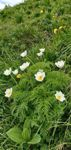
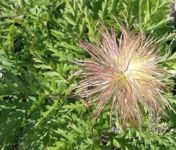
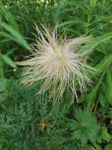


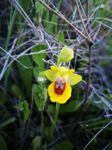
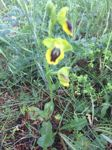
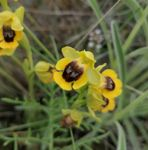


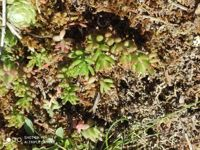
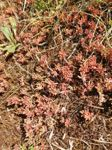
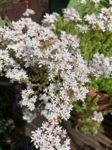


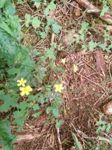
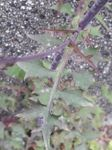
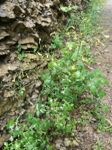
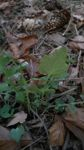


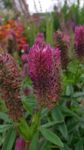
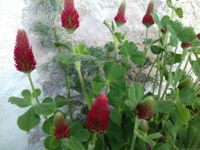
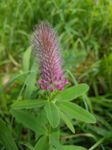
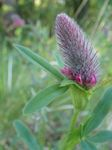
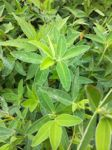
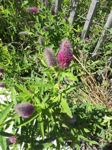


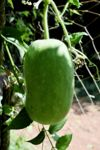
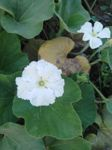
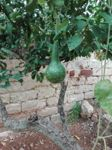
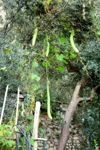
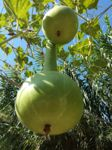
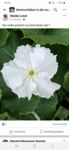
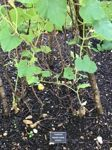
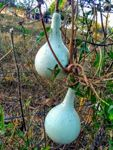


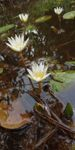
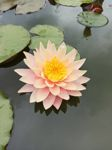
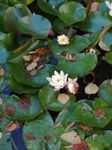
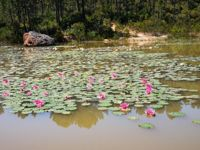


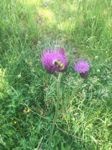
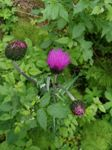
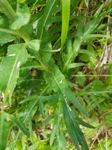
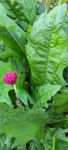
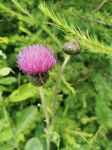
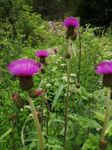


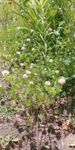
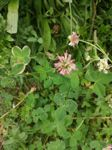
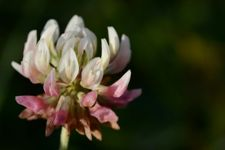
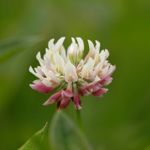
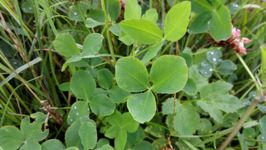
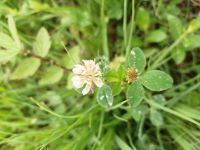
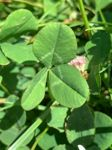
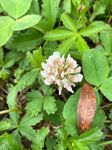


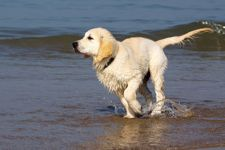


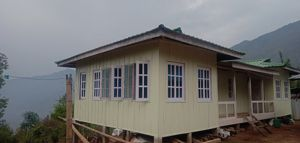


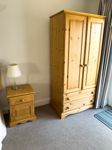

In [9]:
def slicica(putanja, visina=150):
    slika = Image.open(putanja).convert("RGB")
    slika.thumbnail((visina * 2, visina))
    bafer = io.BytesIO()
    slika.save(bafer, "JPEG", quality=80)
    return "data:image/jpeg;base64," + base64.b64encode(bafer.getvalue()).decode()

def slike_html(putanje):
    return "".join(f'<img src="{slicica(p)}" style="height:150px;margin:2px;border-radius:4px">' for p in putanje)

def boja(tacna, navedene):
    if tacna.startswith("(nije biljka"):
        return "#f8d7d7" if navedene else "#d9f2dc"
    n = [normalizuj(x) for x in navedene]
    t = normalizuj(tacna)
    if n[:1] == [t]:
        return "#d9f2dc"
    return "#fff3c4" if t in n else "#f8d7d7"

def kolona_html(naslov, tip, uvod, vrste, pozadina):
    stavke = "".join(f"<p><b><i>{html.escape(naziv)}</i></b><br>{html.escape(opis)}</p>" for naziv, opis in vrste)
    return (f'<div style="flex:1;background:{pozadina};padding:10px 14px;border-radius:8px;color:#111">'
            f'<h4 style="margin:0 0 6px">{naslov} <span style="font-weight:normal;font-size:0.85em">({tip})</span></h4>'
            f'<p>{html.escape(uvod)}</p>{stavke}</div>')

for i, red in enumerate(slucajevi, start=1):
    k = kes[red["specie_id"]]
    bez = k["bez_raga"]
    sa = k["sa_ragom"]
    sa_vrste = [(v["naziv"], v["opis"]) for v in sa["vrste"]]
    bez_vrste = [(v["naziv"], v["opis"]) for v in bez["vrste"]]

    tekst_upita = f'<p><b>Tekst:</b> „{html.escape(red["opis"])}“</p>' if red["opis"] else "<p><b>Tekst:</b> (bez teksta)</p>"
    korisnik_slike = slike_html(red["putanje"])
    referentne = slike_html(sorted((TRAIN_DIR / red["specie_id"]).glob("*.jpg"))[:3])
    van_teme = red["grupa"] == "D"
    pozadina_sa = boja(red["tacna_vrsta"], [n for n, _ in sa_vrste]) if (sa_vrste or van_teme) else "#f8d7d7"

    kartica = f"""
    <div style="border:1px solid #bbb;border-radius:10px;padding:14px;margin:18px 0;font-family:sans-serif;color:#111;background:#fff">
      <h3 style="margin:0 0 8px">Primer {i} — {IMENA_GRUPA[red["grupa"]]} ({(red["stil"] or "-")}, {red["n_slika"]} slika)</h3>
      <div style="display:flex;gap:16px">
        <div style="flex:1">
          <p><b>Upit korisnika</b></p>{tekst_upita}{korisnik_slike}
        </div>
        <div style="flex:1">
          <p><b>Tačna vrsta:</b> <i>{html.escape(red["tacna_vrsta"])}</i>{"" if van_teme else " (referentne fotografije iz baze)"}</p>{referentne}
        </div>
      </div>
      <div style="display:flex;gap:16px;margin-top:12px">
        {kolona_html("LLM bez RAG-a", bez["tip"], bez["uvod"], bez_vrste, boja(red["tacna_vrsta"], [n for n, _ in bez_vrste]))}
        {kolona_html("LLM sa RAG-om", TIP_RAG[sa["tip"]], sa["uvod"], sa_vrste, pozadina_sa)}
      </div>
    </div>"""
    display(HTML(kartica))

In [10]:
PRIMER = 1
s = slucajevi[PRIMER - 1]["specie_id"]
print(slucajevi[PRIMER - 1]["tacna_vrsta"], "\n")
print(json.load(open(KB_DIR / "knowledge_base.json", encoding="utf-8"))[s]["tekst"])

Pulsatilla alpina 

It is an herbaceous perennial growing to 15–30 cm (6–12 in) tall by 20 cm (8 in) wide, and can be found at altitudes of 1,200–2,700 m (3,900–8,900 ft). Pulsatilla alpina has deeply divided, hairy leaves. It has more upright flowers than other species of Pulsatilla, which generally have drooping flowers. They are white or, in the case of subsp. apiifolia, yellow. The flowers are produced very early, often opening while still under snow cover. They have prominent yellow stamens. As with all pasqueflowers, the flowers have a silky, hairy texture, and are followed by prominent seedheads which persist on the plant for many weeks.
